<a href="https://colab.research.google.com/github/ancestor9/2026_Fall_Learning-Langchain-AI-Agent/blob/main/excercise/Langchain_rag_geminiAPI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Build a RAG agent with LangChain**
https://docs.langchain.com/oss/python/langchain/rag

In [1]:
!pip install langchain langchain-text-splitters langchain-community bs4 -q
!pip install -U "langchain[google-genai]" -q
!pip install -U langchain-google-genai -q

In [2]:
from google.colab import userdata
GOOGLE_API_KEY= userdata.get('Gemini-API-Key')

In [3]:
import os
os.environ["GOOGLE_API_KEY"] = GOOGLE_API_KEY

In [4]:
from langchain.chat_models import init_chat_model

model = init_chat_model("google_genai:gemini-3.5-flash-lite")

In [5]:
model

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.5', 'langchain-google-genai': '4.4.1'}}, profile={'name': 'Gemini 3.5 Flash Lite', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x782fdcb2d010>, default_metadata=(), model_kwargs=

In [6]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings

embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

In [7]:
embeddings

GoogleGenerativeAIEmbeddings(client=<google.genai.client.Client object at 0x782fdc832ad0>, model='models/gemini-embedding-001', task_type=None, google_api_key=SecretStr('**********'), credentials=None, vertexai=None, project=None, location=None, base_url=None, additional_headers=None, client_args=None, api_version=None, request_options=None, output_dimensionality=None)

In [8]:
# pip install -U "langchain-core"

In [9]:
from langchain_core.vectorstores import InMemoryVectorStore

vector_store = InMemoryVectorStore(embeddings)

In [10]:
vector_store

# 1. Indexing
<img src='https://mintcdn.com/langchain-5e9cc07a/I6RpA28iE233vhYX/images/rag_indexing.png?w=840&fit=max&auto=format&n=I6RpA28iE233vhYX&q=85&s=1838328a870c7353c42bf1cc2290a779'>

# Loading documents

In [11]:
import bs4
from langchain_community.document_loaders import WebBaseLoader

# Only keep post title, headers, and content from the full HTML.
bs4_strainer = bs4.SoupStrainer(class_=("post-title", "post-header", "post-content"))

loader = WebBaseLoader(
    web_paths=("https://lilianweng.github.io/posts/2023-06-23-agent/",),
    bs_kwargs={"parse_only": bs4_strainer},
)
docs = loader.load()

assert len(docs) == 1

print(f"Total characters: {len(docs[0].page_content)}")

/tmp/ipykernel_3026/726046369.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader


Total characters: 43047


In [12]:
# User-Agent 설정
os.environ["USER_AGENT"] = "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/142.0.0.0 Safari/537.36"

In [13]:
print(docs[0].page_content[:500])



      LLM Powered Autonomous Agents
    
Date: June 23, 2023  |  Estimated Reading Time: 31 min  |  Author: Lilian Weng


Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.
Agent System Overview#
In


In [14]:
docs

[Document(metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/'}, page_content='\n\n      LLM Powered Autonomous Agents\n    \nDate: June 23, 2023  |  Estimated Reading Time: 31 min  |  Author: Lilian Weng\n\n\nBuilding agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.\nAgent System Overview#\nIn a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:\n\nPlanning\n\nSubgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.\nReflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistake

# Splitting documents

In [15]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,  # chunk size (characters)
    chunk_overlap=200,  # chunk overlap (characters)
    add_start_index=True,  # track index in original document
)
all_splits = text_splitter.split_documents(docs)

print(f"Split blog post into {len(all_splits)} sub-documents.")

Split blog post into 63 sub-documents.


# Storing documents

In [16]:
document_ids = vector_store.add_documents(documents=all_splits)

print(document_ids[:3])

['8e3ba6d9-4bc5-48f8-a252-61f4551c2db7', 'f18493e8-0f2b-4f9a-a4cb-a2af822f4655', '07f6ec92-fa9d-4e21-a03c-772245bcfe47']


In [17]:
document_ids

['8e3ba6d9-4bc5-48f8-a252-61f4551c2db7',
 'f18493e8-0f2b-4f9a-a4cb-a2af822f4655',
 '07f6ec92-fa9d-4e21-a03c-772245bcfe47',
 '9930a44e-b135-4ed0-bb04-98073c8e65e7',
 '32a91bd2-544b-4ada-b2eb-20746c6cfafd',
 '0ba211b3-e558-4b43-8ba5-e4d12e600d0c',
 '206f59f8-ea40-4eb3-bce0-dd5d74f84926',
 '2957fa95-931d-455c-9cc4-6a3809a38889',
 '59efa618-8921-4853-ad37-dcb64d5bffdf',
 '71670ace-fcf6-4276-9c5b-1615c1305a86',
 '70fe2936-c863-4828-8f54-adc070dd5090',
 'f1032750-8213-487c-81b8-b375b4b0cc1c',
 '143a2766-7458-4026-ba41-4f2a0d9ecd1f',
 '783bd205-05fa-41e3-96d3-aacbf3e9764b',
 'e87a6f48-8f97-4447-b0e7-c300f21b0cd8',
 'aab789ff-bb8d-4fca-8bc2-70cb2b16fffb',
 '439026c2-5e52-443f-bf47-3d38650c8fe3',
 '446d70ea-1452-4367-8efa-5747f3091435',
 '1d37e46f-047b-4911-b1da-7a1bd6cd9631',
 '3f91cc21-1cd2-418f-a7bb-caeb6bc1a2be',
 '24fd0038-fda4-45fc-a89d-682ed840b07d',
 'a23a148a-ada3-4309-a023-920a4f796461',
 '54c6f283-6d39-451f-b566-28c6fa5353a8',
 '130a7a12-fafd-42bd-9f23-4b298029236b',
 '99fe8ea3-9fdf-

# 2. Retrieval and Generation
<img src='https://mintcdn.com/langchain-5e9cc07a/I6RpA28iE233vhYX/images/rag_retrieval_generation.png?w=840&fit=max&auto=format&n=I6RpA28iE233vhYX&q=85&s=67fe2302e241fc24238a5df1cf56573d'>

# RAG agents

In [18]:
from langchain.tools import tool

@tool(response_format="content_and_artifact")
def retrieve_context(query: str):
    """Retrieve information to help answer a query."""
    retrieved_docs = vector_store.similarity_search(query, k=2)
    serialized = "\n\n".join(
        (f"Source: {doc.metadata}\nContent: {doc.page_content}")
        for doc in retrieved_docs
    )
    return serialized, retrieved_docs

In [19]:
from langchain.agents import create_agent

tools = [retrieve_context]
# If desired, specify custom instructions
prompt = (
    "You have access to a tool that retrieves context from a blog post. "
    "Use the tool to help answer user queries."
)
agent = create_agent(model, tools, system_prompt=prompt)

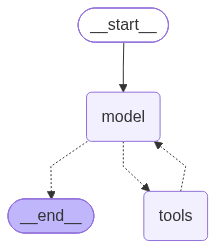

In [20]:
agent

In [21]:
query = (
    "What is the standard method for Task Decomposition?\n\n"
    "Once you get the answer, look up common extensions of that method."
)

for event in agent.stream(
    {"messages": [{"role": "user", "content": query}]},
    stream_mode="values",
):
    event["messages"][-1].pretty_print()

================================ Human Message =================================

What is the standard method for Task Decomposition?

Once you get the answer, look up common extensions of that method.
================================== Ai Message ==================================

[]
Tool Calls:
  retrieve_context (call_283357)
 Call ID: call_283357
  Args:
    query: Task Decomposition standard method common extensions
================================= Tool Message =================================
Name: retrieve_context

Source: {'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/', 'start_index': 2578}
Content: Task decomposition can be done (1) by LLM with simple prompting like "Steps for XYZ.\n1.", "What are the subgoals for achieving XYZ?", (2) by using task-specific instructions; e.g. "Write a story outline." for writing a novel, or (3) with human inputs.
Another quite distinct approach, LLM+P (Liu et al. 2023), involves relying on an external classical planner to 